In [1]:
# Mount Google Drive so we can read and save files permanently
from google.colab import drive
drive.mount('/content/drive')

PROJECT_ROOT = '/content/drive/MyDrive/IT3091_BankMarketing'
print("Project root set to:", PROJECT_ROOT)

Mounted at /content/drive
Project root set to: /content/drive/MyDrive/IT3091_BankMarketing


In [2]:
# create the full project folder structure on Drive
import os

folders = [
    f'{PROJECT_ROOT}/data/raw',
    f'{PROJECT_ROOT}/data/processed',
    f'{PROJECT_ROOT}/notebooks',
    f'{PROJECT_ROOT}/outputs/figures',
    f'{PROJECT_ROOT}/outputs/models',
    f'{PROJECT_ROOT}/logs',
]

for f in folders:
    os.makedirs(f, exist_ok=True)
    print("Created:", f)

Created: /content/drive/MyDrive/IT3091_BankMarketing/data/raw
Created: /content/drive/MyDrive/IT3091_BankMarketing/data/processed
Created: /content/drive/MyDrive/IT3091_BankMarketing/notebooks
Created: /content/drive/MyDrive/IT3091_BankMarketing/outputs/figures
Created: /content/drive/MyDrive/IT3091_BankMarketing/outputs/models
Created: /content/drive/MyDrive/IT3091_BankMarketing/logs


In [8]:
RAW_PATH = f'{PROJECT_ROOT}/data/raw/bank-additional-full.csv'
print("File exists:", os.path.exists(RAW_PATH))

File exists: True


In [9]:
# Load the raw dataset
# We use the FULL file (41,188 rows), not the 10% sample, for a more reliable 3-way split
# The file is semicolon-delimited (sep=';'), a common European CSV convention
import pandas as pd

RAW_PATH = f'{PROJECT_ROOT}/data/raw/bank-additional-full.csv'
df = pd.read_csv(RAW_PATH, sep=';')

print("Raw dataset loaded")
print("Shape (rows, columns):", df.shape)

Raw dataset loaded
Shape (rows, columns): (41188, 21)


In [10]:
# Build a data dictionary: column name, dtype, number of unique values, and a sample value
data_dictionary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'n_unique': df.nunique(),
    'sample_value': df.iloc[0]
})
print(data_dictionary)

print("\nFirst 5 rows:")
display(df.head())

                  dtype  n_unique sample_value
age               int64        78           56
job              object        12    housemaid
marital          object         4      married
education        object         8     basic.4y
default          object         3           no
housing          object         3           no
loan             object         3           no
contact          object         2    telephone
month            object        10          may
day_of_week      object         5          mon
duration          int64      1544          261
campaign          int64        42            1
pdays             int64        27          999
previous          int64         8            0
poutcome         object         3  nonexistent
emp.var.rate    float64        10          1.1
cons.price.idx  float64        26       93.994
cons.conf.idx   float64        26        -36.4
euribor3m       float64       316        4.857
nr.employed     float64        11       5191.0
y            

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [11]:
# Target variable analysis - this single result shapes almost every decision in the project
print("Target value counts:")
print(df['y'].value_counts())

print("\nTarget percentages:")
print(df['y'].value_counts(normalize=True).round(4) * 100)

# Why this matters: if the classes are imbalanced, accuracy becomes a misleading metric,
# and we will need imbalance-handling strategies (class weighting, threshold tuning) later

Target value counts:
y
no     36548
yes     4640
Name: count, dtype: int64

Target percentages:
y
no     88.73
yes    11.27
Name: proportion, dtype: float64


In [12]:
# Data quality check: duplicates and true missing values
print("Duplicate rows (exact matches across all 21 columns):", df.duplicated().sum())
print("Total true NaN values:", df.isnull().sum().sum())

# Why this matters: exact duplicates can bias a model toward over-weighting repeated patterns
# and true NaN values would need imputation - but this dataset uses "unknown" as a string
# label for missingness instead, which we check next

Duplicate rows (exact matches across all 21 columns): 12
Total true NaN values: 0


In [13]:
# Missingness in this dataset is encoded as the string "unknown", not NaN
# We check each categorical column individually, since the severity differs a lot
cat_cols = df.select_dtypes(include='object').columns

print(f"{'Column':<15}{'Unknown count':>15}{'Percentage':>15}")
for col in cat_cols:
    n_unknown = (df[col] == 'unknown').sum()
    if n_unknown > 0:
        pct = n_unknown / len(df) * 100
        print(f"{col:<15}{n_unknown:>15}{pct:>14.2f}%")



Column           Unknown count     Percentage
job                        330          0.80%
marital                     80          0.19%
education                 1731          4.20%
default                   8597         20.87%
housing                    990          2.40%
loan                       990          2.40%


In [14]:
# Split into Train (60%), Validation (20%), Test (20%)
# Stratified to preserve the 88.7/11.3 class ratio in all three sets
from sklearn.model_selection import train_test_split

X = df.drop(columns=['y'])
y = df['y'].map({'no': 0, 'yes': 1})

# Step 1: carve off 60% for training, leaving 40% temporarily
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.40, stratify=y, random_state=42
)

# Step 2: split the remaining 40% evenly into validation (20%) and test (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=42
)

for name, x_part, y_part in [("Train", X_train, y_train), ("Validation", X_val, y_val), ("Test", X_test, y_test)]:
    print(f"{name:12}: {x_part.shape[0]:>6} rows, positive class = {y_part.mean():.2%}")

Train       :  24712 rows, positive class = 11.27%
Validation  :   8238 rows, positive class = 11.26%
Test        :   8238 rows, positive class = 11.26%


In [15]:
# Remove duplicates ONLY from the training set

n_dupes_train = X_train.duplicated().sum()
print("Duplicate rows found in training set:", n_dupes_train)

dupe_mask = X_train.duplicated()
X_train = X_train[~dupe_mask]
y_train = y_train[~dupe_mask]

print("Training set shape after removing duplicates:", X_train.shape)

Duplicate rows found in training set: 7
Training set shape after removing duplicates: (24705, 20)


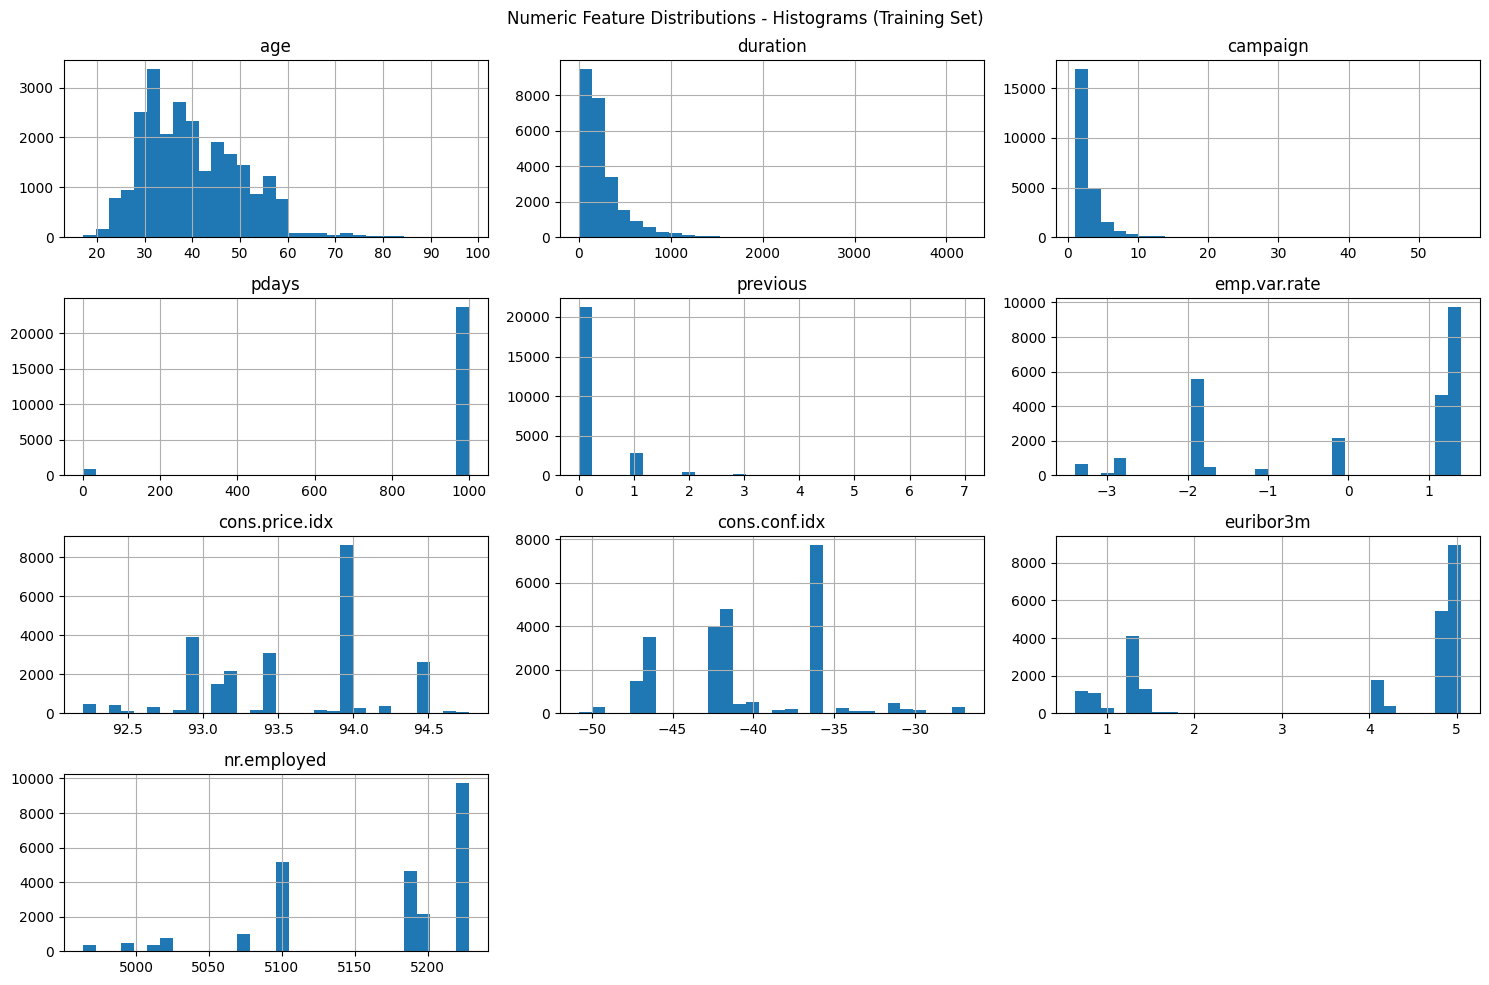

In [16]:
# Univariate EDA: histograms of all numeric features (training set only)
# We look for: skew, outliers, unusual spikes (like special codes), and general shape
import matplotlib.pyplot as plt

numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

X_train[numeric_cols].hist(figsize=(15, 10), bins=30)
plt.suptitle('Numeric Feature Distributions - Histograms (Training Set)')
plt.tight_layout()
plt.show()

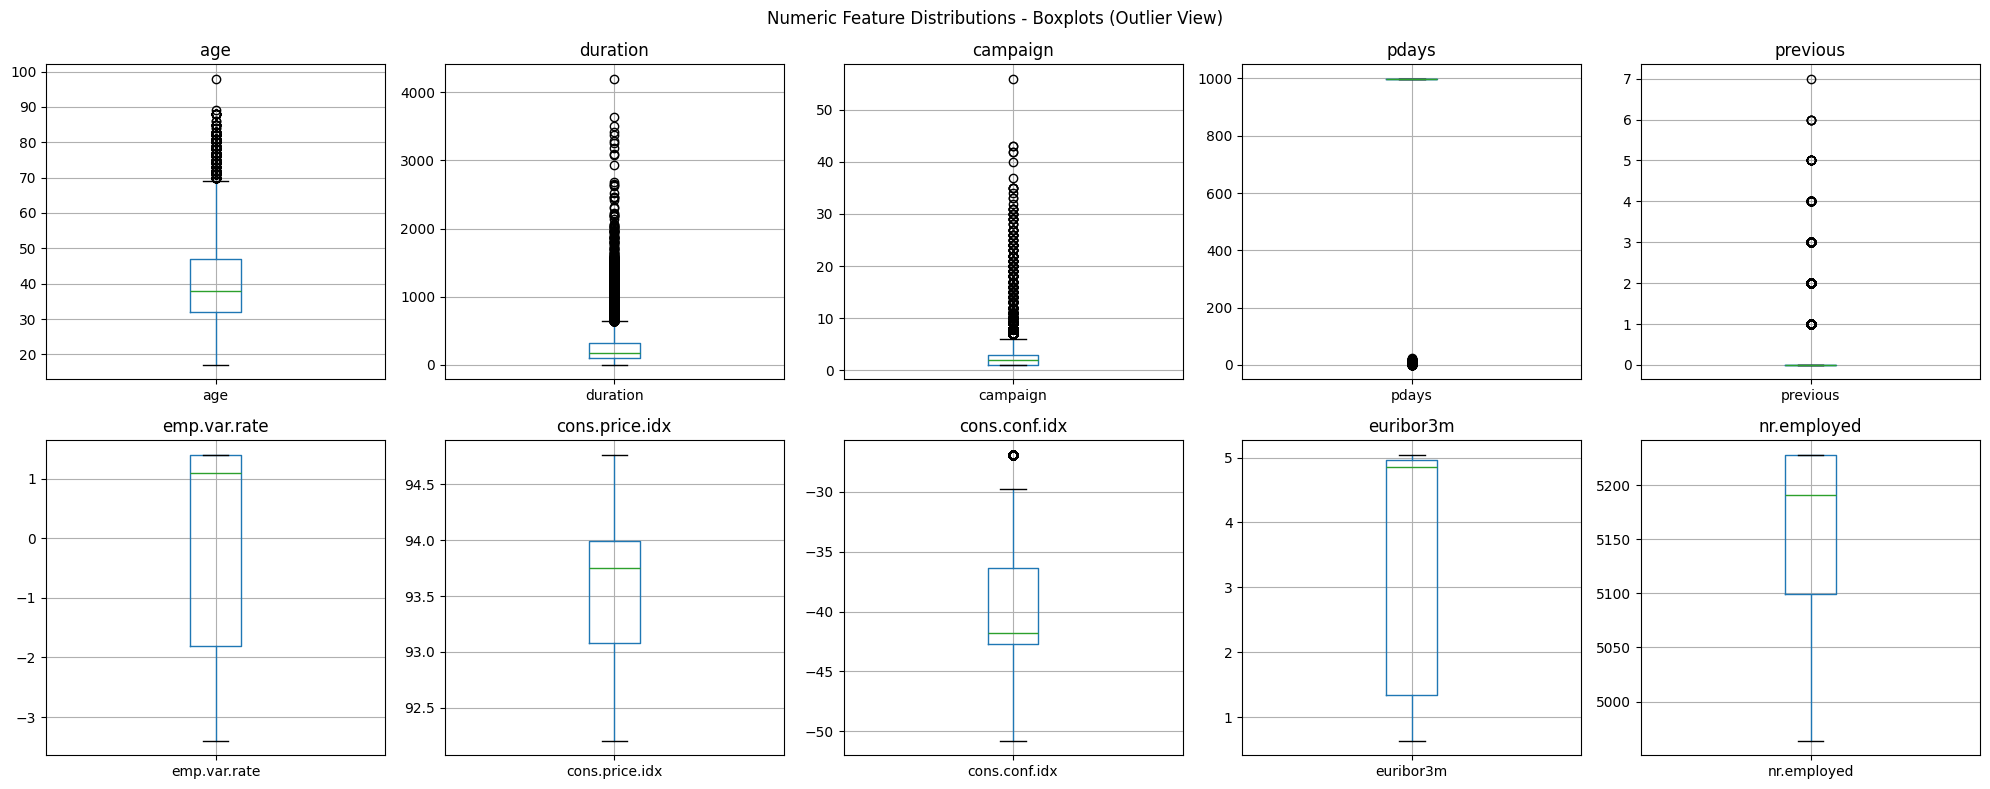

In [17]:
# Boxplots make the extent of outliers far more visible than histograms alone,
# since the whiskers and individual points show exactly how far extreme values stretch
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(numeric_cols):
    X_train.boxplot(column=col, ax=axes[i])
    axes[i].set_title(col)

plt.suptitle('Numeric Feature Distributions - Boxplots (Outlier View)')
plt.tight_layout()
plt.show()

In [18]:
# Turn the visual impression into precise numbers using the IQR method
# A point is flagged as an outlier if it falls more than 1.5x the interquartile range
# beyond the 25th or 75th percentile - a standard, widely accepted statistical convention
outlier_summary = {}

for col in numeric_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    n_outliers = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    pct_outliers = n_outliers / len(X_train) * 100
    outlier_summary[col] = {'count': n_outliers, 'pct': round(pct_outliers, 2)}

outlier_df = pd.DataFrame(outlier_summary).T.sort_values('pct', ascending=False)
print(outlier_df)

                 count    pct
previous        3422.0  13.85
duration        1812.0   7.33
campaign        1398.0   5.66
pdays            943.0   3.82
cons.conf.idx    274.0   1.11
age              255.0   1.03
emp.var.rate       0.0   0.00
cons.price.idx     0.0   0.00
euribor3m          0.0   0.00
nr.employed        0.0   0.00


In [19]:
# Quantify skewness precisely - a value above roughly 1 is generally considered
# strongly skewed, and a candidate for log-transformation before modeling
from scipy.stats import skew

skew_summary = X_train[numeric_cols].apply(lambda x: skew(x.dropna())).sort_values(ascending=False)
print(skew_summary)

campaign          4.956168
previous          3.874750
duration          3.221945
age               0.732821
cons.conf.idx     0.308326
cons.price.idx   -0.229637
euribor3m        -0.701644
emp.var.rate     -0.717422
nr.employed      -1.036946
pdays            -4.820706
dtype: float64


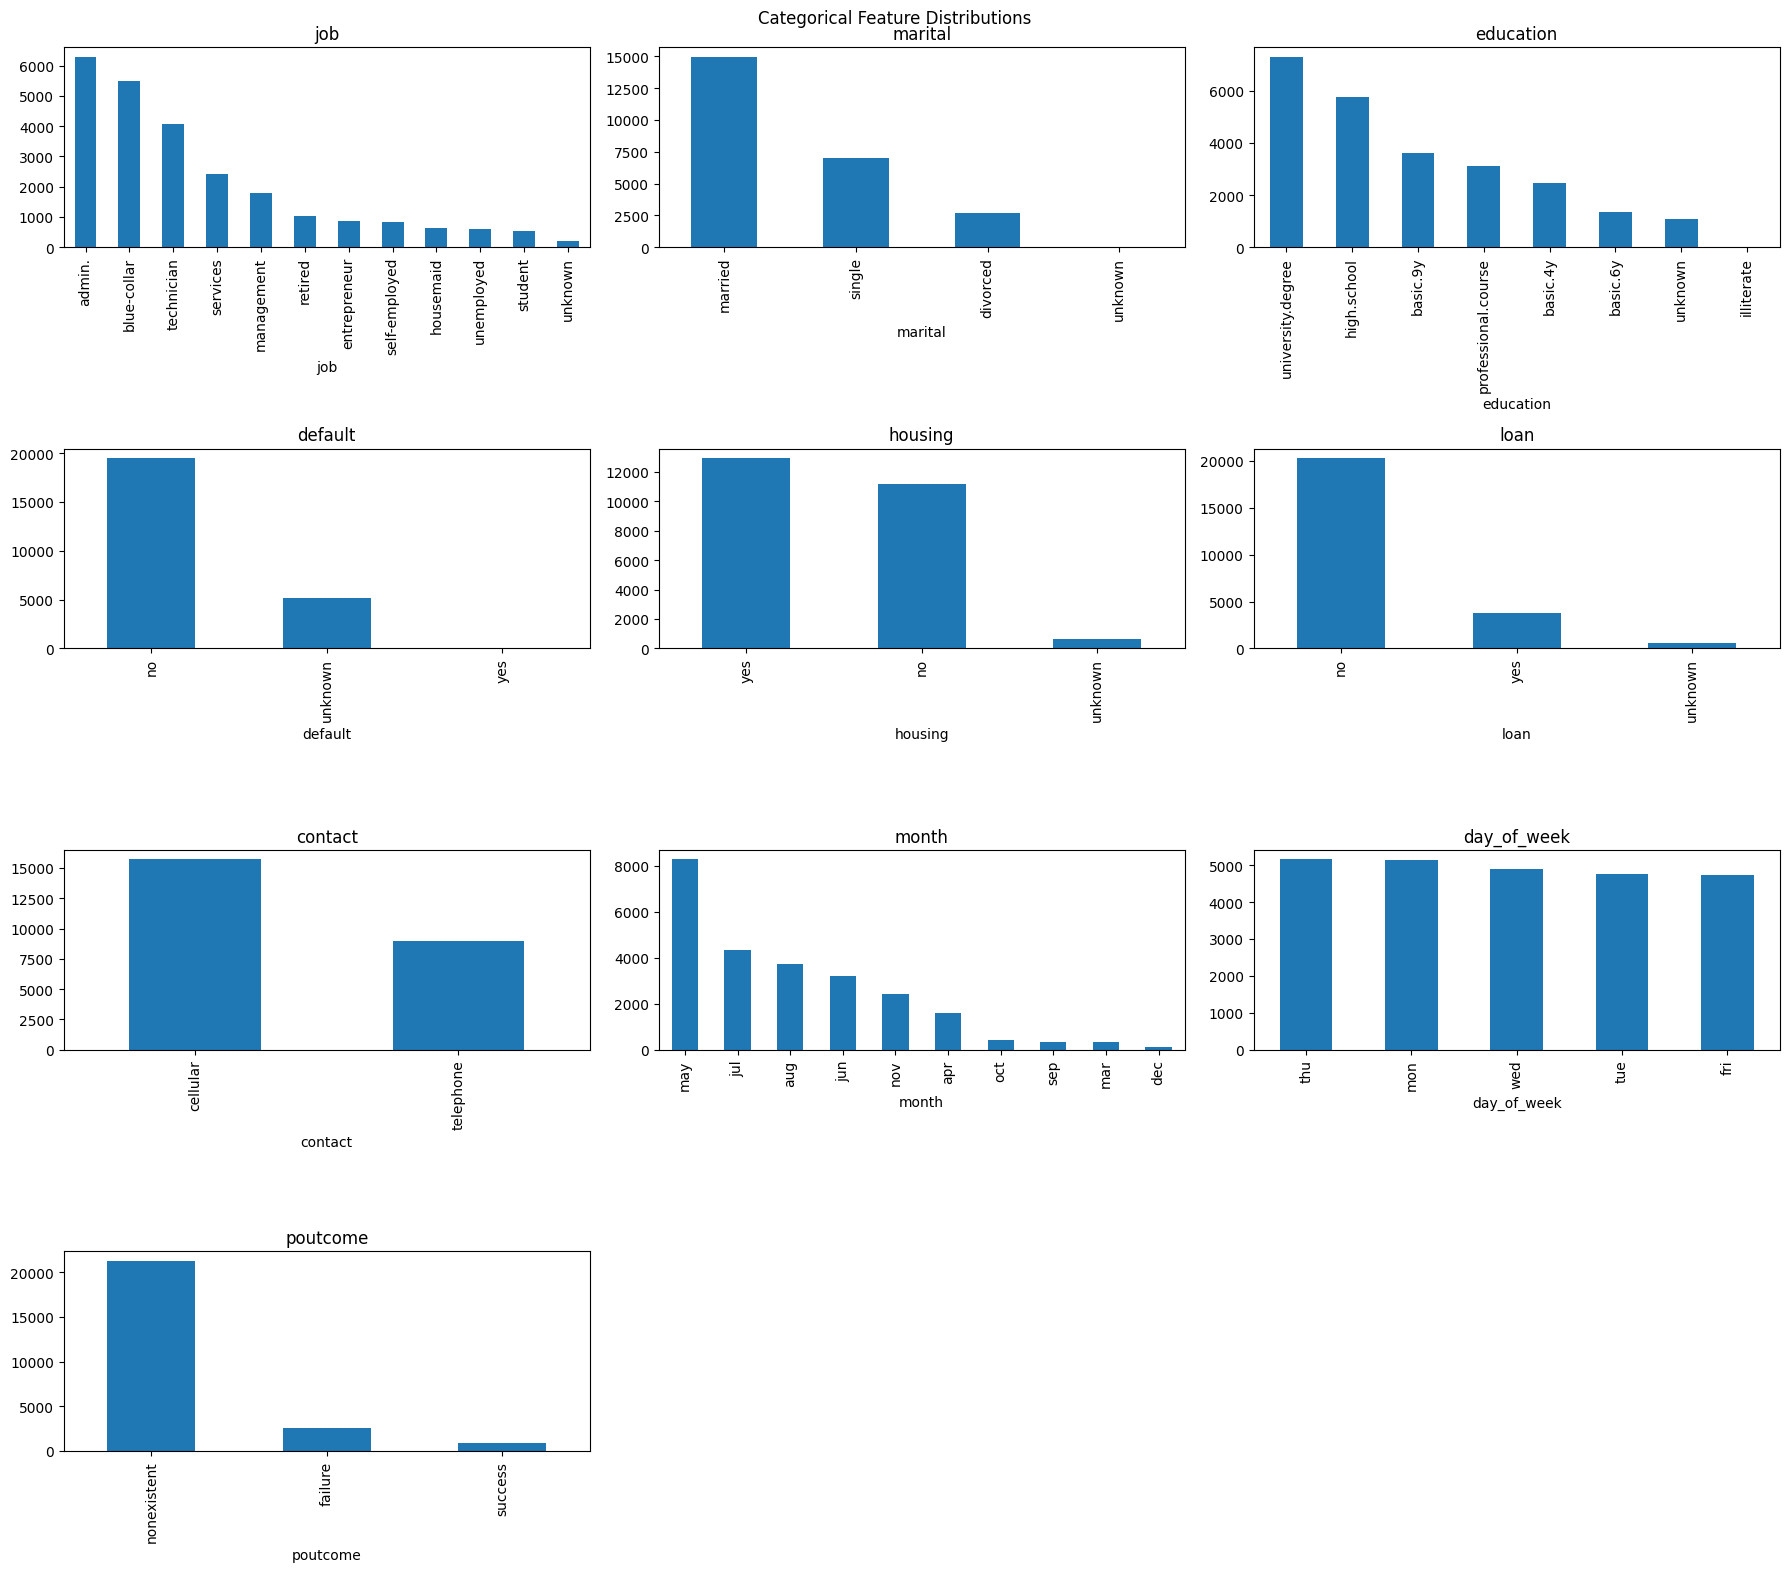

In [20]:
# Univariate EDA: bar charts for every categorical feature
categorical_cols_original = X_train.select_dtypes(include='object').columns

fig, axes = plt.subplots(4, 3, figsize=(18, 16))
axes = axes.flatten()

for i, col in enumerate(categorical_cols_original):
    X_train[col].value_counts().plot(kind='bar', ax=axes[i])
    axes[i].set_title(col)

for ax in axes[len(categorical_cols_original):]:
    ax.remove()

plt.suptitle('Categorical Feature Distributions')
plt.tight_layout()
plt.show()

In [21]:
# Cardinality check: how many distinct categories does each column have?
# This matters because one-hot encoding creates one new column per category,
# so high cardinality columns can blow up the feature space significantly
for col in categorical_cols_original:
    print(f"{col}: {X_train[col].nunique()} unique categories")

job: 12 unique categories
marital: 4 unique categories
education: 8 unique categories
default: 3 unique categories
housing: 3 unique categories
loan: 3 unique categories
contact: 2 unique categories
month: 10 unique categories
day_of_week: 5 unique categories
poutcome: 3 unique categories


In [22]:
# Bivariate analysis: does each numeric feature actually differ between subscribers and non-subscribers?
# We use Mann-Whitney U instead of a t-test because most of our numeric features are skewed,
# and Mann-Whitney doesn't assume normally distributed data
from scipy.stats import mannwhitneyu

train_df = X_train.copy()
train_df['y'] = y_train

print(f"{'Feature':<18}{'Mean(no)':>12}{'Mean(yes)':>12}{'p-value':>14}{'Significant?':>14}")
for col in numeric_cols:
    group_no = train_df[train_df['y'] == 0][col]
    group_yes = train_df[train_df['y'] == 1][col]
    stat, p_value = mannwhitneyu(group_no, group_yes, alternative='two-sided')
    sig = "Yes" if p_value < 0.05 else "No"
    print(f"{col:<18}{group_no.mean():>12.2f}{group_yes.mean():>12.2f}{p_value:>14.2e}{sig:>14}")

Feature               Mean(no)   Mean(yes)       p-value  Significant?
age                      39.90       40.90      1.17e-01            No
duration                219.54      556.72      0.00e+00           Yes
campaign                  2.62        2.05      1.97e-20           Yes
pdays                   983.01      788.56      0.00e+00           Yes
previous                  0.14        0.50     1.01e-221           Yes
emp.var.rate              0.24       -1.20      0.00e+00           Yes
cons.price.idx           93.60       93.36      2.36e-76           Yes
cons.conf.idx           -40.60      -39.81      1.92e-10           Yes
euribor3m                 3.80        2.15      0.00e+00           Yes
nr.employed            5175.82     5096.43      0.00e+00           Yes


In [23]:
# Bivariate analysis: does each categorical feature have a significant relationship with the target?
from scipy.stats import chi2_contingency

print(f"{'Feature':<15}{'chi2':>12}{'p-value':>14}{'Significant?':>14}")
for col in categorical_cols_original:
    contingency = pd.crosstab(train_df[col], train_df['y'])
    chi2, p_value, dof, expected = chi2_contingency(contingency)
    sig = "Yes" if p_value < 0.05 else "No"
    print(f"{col:<15}{chi2:>12.2f}{p_value:>14.2e}{sig:>14}")

Feature                chi2       p-value  Significant?
job                  535.78     7.43e-108           Yes
marital               75.71      2.56e-16           Yes
education            110.68      6.64e-21           Yes
default              237.30      2.96e-52           Yes
housing                1.58      4.54e-01            No
loan                   0.71      7.03e-01            No
contact              493.81     2.11e-109           Yes
month               1837.66      0.00e+00           Yes
day_of_week           12.95      1.15e-02           Yes
poutcome            2468.86      0.00e+00           Yes


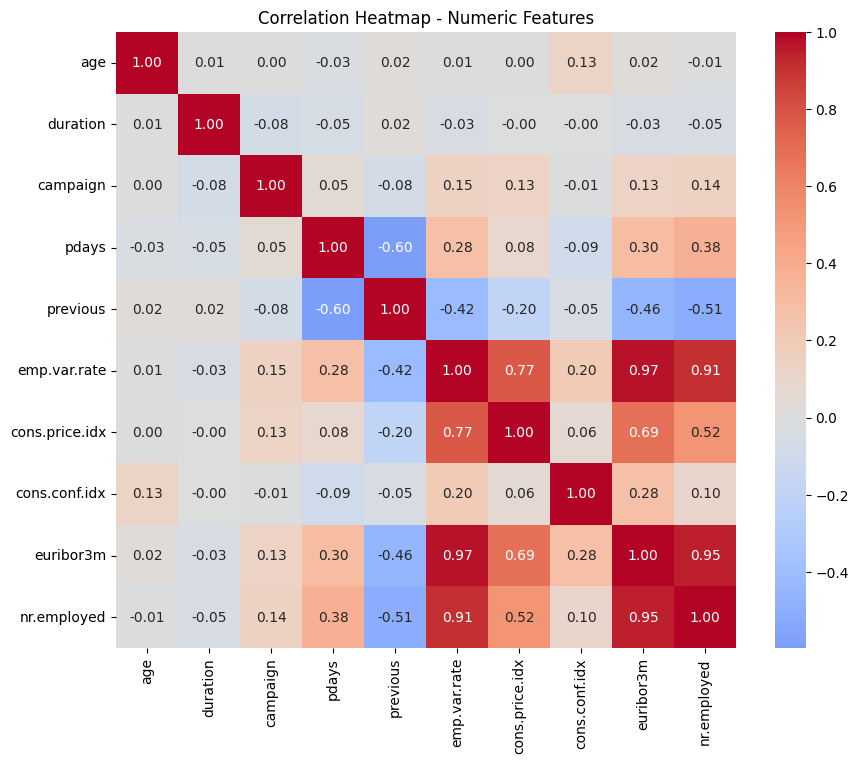

In [24]:
# Multivariate analysis: how do numeric features relate to EACH OTHER, not just the target?
# This matters because highly correlated features can cause instability in linear models
import seaborn as sns

plt.figure(figsize=(10, 8))
sns.heatmap(train_df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Heatmap - Numeric Features')
plt.show()

In [25]:
# Quantify multicollinearity precisely using Variance Inflation Factor (VIF)
# A VIF above 10 is generally considered severe - meaning that feature's variance is
# largely explainable by the other features, which destabilizes linear model coefficients
from statsmodels.stats.outliers_influence import variance_inflation_factor

vif_data = pd.DataFrame()
vif_data['feature'] = numeric_cols
vif_data['VIF'] = [variance_inflation_factor(train_df[numeric_cols].values, i) for i in range(len(numeric_cols))]
vif_data = vif_data.sort_values('VIF', ascending=False)
print(vif_data)

          feature        VIF
8       euribor3m  65.046226
5    emp.var.rate  33.358226
9     nr.employed  31.892869
6  cons.price.idx   6.346566
7   cons.conf.idx   2.667635
4        previous   1.831126
3           pdays   1.644434
2        campaign   1.037433
0             age   1.017272
1        duration   1.010007


In [26]:
# Mutual information captures non-linear feature-target relationships that correlation
# and simple statistical tests can miss - useful as a preview of feature importance
# before any model is trained
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import LabelEncoder

mi_df = X_train.copy()
for col in categorical_cols_original:
    mi_df[col] = LabelEncoder().fit_transform(mi_df[col])

mi_scores = mutual_info_classif(mi_df.drop(columns=['pdays']), y_train, random_state=42)
mi_series = pd.Series(mi_scores, index=mi_df.drop(columns=['pdays']).columns).sort_values(ascending=False)
print(mi_series)

duration          0.080514
euribor3m         0.068844
cons.price.idx    0.067486
cons.conf.idx     0.066604
nr.employed       0.062429
emp.var.rate      0.052531
poutcome          0.033901
month             0.027220
previous          0.017129
contact           0.012573
age               0.011917
job               0.008600
default           0.005285
education         0.005013
marital           0.003770
campaign          0.002678
housing           0.001855
day_of_week       0.000000
loan              0.000000
dtype: float64


<Figure size 800x500 with 0 Axes>

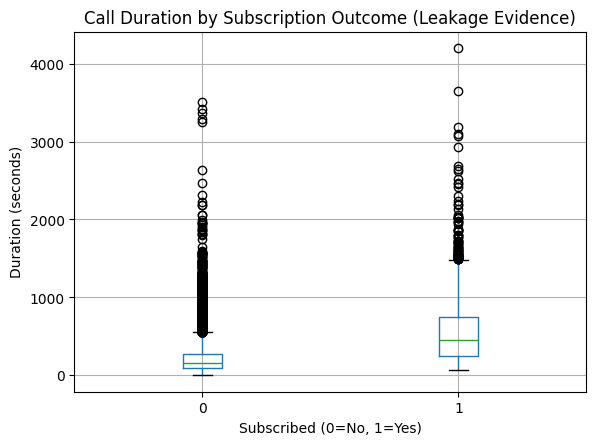

In [27]:
# Visualize the duration leakage issue directly, not just cite it from documentation
plt.figure(figsize=(8, 5))
train_df.boxplot(column='duration', by='y')
plt.title('Call Duration by Subscription Outcome (Leakage Evidence)')
plt.suptitle('')
plt.xlabel('Subscribed (0=No, 1=Yes)')
plt.ylabel('Duration (seconds)')
plt.show()

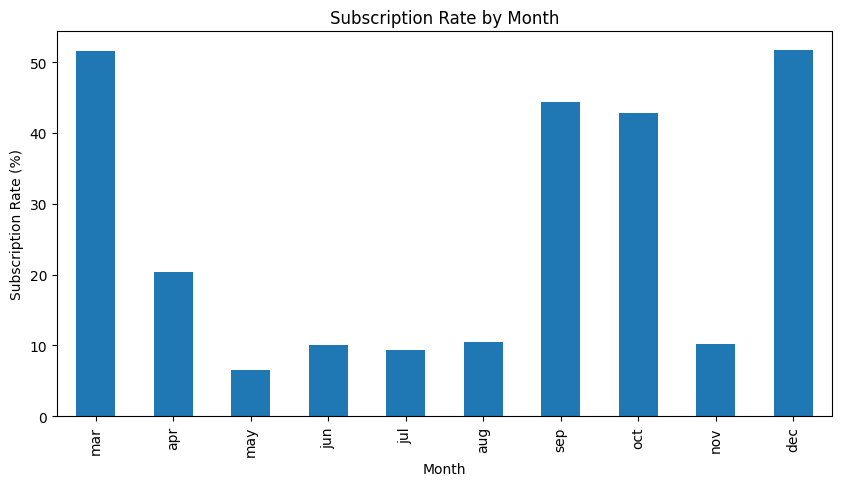

month
mar    51.59
apr    20.31
may     6.57
jun    10.01
jul     9.40
aug    10.45
sep    44.31
oct    42.79
nov    10.24
dec    51.75
Name: y, dtype: float64


In [28]:
# Check whether subscription behavior shifted across the campaign's timeframe (2008-2010)
month_order = ['mar', 'apr', 'may', 'jun', 'jul', 'aug', 'sep', 'oct', 'nov', 'dec']
monthly_rate = train_df.groupby('month')['y'].mean().reindex(month_order) * 100

plt.figure(figsize=(10, 5))
monthly_rate.plot(kind='bar')
plt.title('Subscription Rate by Month')
plt.ylabel('Subscription Rate (%)')
plt.xlabel('Month')
plt.show()

print(monthly_rate.round(2))

In [30]:
# Decision 1: convert pdays=999 into a binary flag rather than using the raw number
# Evidence: pdays showed an extreme, artificial skew (-4.82) driven entirely by the 999 code,
# and both the boxplot and histogram confirmed this is a special "never contacted" marker, not a real value

# Decision 2: merge any rare 'yes' values in default into 'unknown'


for dataset in [X_train, X_val, X_test]:
    dataset['was_previously_contacted'] = (dataset['pdays'] != 999).astype(int)
    dataset['default'] = dataset['default'].replace('yes', 'unknown')

print("was_previously_contacted distribution (train):")
print(X_train['was_previously_contacted'].value_counts())
print("\ndefault distribution (train):")
print(X_train['default'].value_counts())

was_previously_contacted distribution (train):
was_previously_contacted
0    23762
1      943
Name: count, dtype: int64

default distribution (train):
default
no         19493
unknown     5212
Name: count, dtype: int64


In [31]:
# Decision 3: drop housing and loan
# Evidence: chi-square test on THIS training split confirmed both are not significant
# (housing p=0.454, loan p=0.703), and mutual information for loan was exactly 0.0
X_train = X_train.drop(columns=['loan', 'housing'])
X_val = X_val.drop(columns=['loan', 'housing'])
X_test = X_test.drop(columns=['loan', 'housing'])

print("Columns remaining:", X_train.columns.tolist())
print("Total columns:", len(X_train.columns))

Columns remaining: ['age', 'job', 'marital', 'education', 'default', 'contact', 'month', 'day_of_week', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed', 'was_previously_contacted']
Total columns: 19


In [33]:
# Feature 1: age_group
# Rationale: our Mann-Whitney test showed raw age wasn't significant, yet the EDA in our


def age_group(age):
    if age < 25: return 'young'
    elif age < 35: return 'young_adult'
    elif age < 50: return 'middle_age'
    elif age < 65: return 'senior'
    else: return 'elderly'

for dataset in [X_train, X_val, X_test]:
    dataset['age_group'] = dataset['age'].apply(age_group)

print(X_train['age_group'].value_counts())

age_group
middle_age     11000
young_adult     8231
senior          4451
young            644
elderly          379
Name: count, dtype: int64


In [34]:
# Validate: does age_group actually separate high and low converters?
train_df = X_train.copy()
train_df['y'] = y_train

print("Subscription rate by age_group:")
print((train_df.groupby('age_group')['y'].mean() * 100).round(2).sort_values(ascending=False))

Subscription rate by age_group:
age_group
elderly        49.08
young          22.83
young_adult    12.09
senior         11.62
middle_age      8.54
Name: y, dtype: float64


In [35]:
# Feature 2: campaign_intensity
# Rationale: campaign showed severe skew (4.96) and subscribers averaged noticeably fewer


def campaign_bucket(c):
    if c == 1: return 'first_contact'
    elif c <= 3: return 'low_contact'
    elif c <= 6: return 'moderate_contact'
    else: return 'high_contact'

for dataset in [X_train, X_val, X_test]:
    dataset['campaign_intensity'] = dataset['campaign'].apply(campaign_bucket)

print(X_train['campaign_intensity'].value_counts())

campaign_intensity
first_contact       10593
low_contact          9615
moderate_contact     3099
high_contact         1398
Name: count, dtype: int64


In [36]:
# Validate: does subscription rate decline as contact count rises (fatigue pattern)?
train_df = X_train.copy()
train_df['y'] = y_train

print("Subscription rate by campaign_intensity:")
print((train_df.groupby('campaign_intensity')['y'].mean() * 100).round(2).sort_values(ascending=False))

Subscription rate by campaign_intensity:
campaign_intensity
first_contact       12.84
low_contact         11.33
moderate_contact     8.68
high_contact         4.72
Name: y, dtype: float64


In [37]:
# Feature 3: economic_cycle_score
# Rationale: VIF showed severe multicollinearity among emp.var.rate (33.4), euribor3m (65.0),
# and nr.employed (31.9) - they move almost as one variable. Rather than feed all three


from sklearn.preprocessing import StandardScaler

econ_cols = ['emp.var.rate', 'euribor3m', 'nr.employed']
scaler_temp = StandardScaler()
scaler_temp.fit(X_train[econ_cols])  # fit on TRAIN only - no leakage

for dataset in [X_train, X_val, X_test]:
    dataset['economic_cycle_score'] = scaler_temp.transform(dataset[econ_cols]).mean(axis=1)

print(X_train['economic_cycle_score'].describe())

count    2.470500e+04
mean     3.195645e-15
std      9.803729e-01
min     -1.982498e+00
25%     -1.146456e+00
50%      5.658679e-01
75%      8.203614e-01
max      8.220886e-01
Name: economic_cycle_score, dtype: float64


In [38]:
# Validate: does the composite retain the strong predictive signal of the 3 raw indicators?
from scipy.stats import mannwhitneyu

train_df = X_train.copy()
train_df['y'] = y_train

group_no = train_df[train_df['y'] == 0]['economic_cycle_score']
group_yes = train_df[train_df['y'] == 1]['economic_cycle_score']

print("Mean economic_cycle_score - No:", round(group_no.mean(), 3))
print("Mean economic_cycle_score - Yes:", round(group_yes.mean(), 3))

stat, p_value = mannwhitneyu(group_no, group_yes)
print("Mann-Whitney p-value:", f"{p_value:.2e}")

Mean economic_cycle_score - No: 0.111
Mean economic_cycle_score - Yes: -0.876
Mann-Whitney p-value: 0.00e+00


In [39]:
# Define feature groups for preprocessing
numeric_features = ['age', 'campaign', 'previous', 'emp.var.rate',
                     'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

categorical_features = ['job', 'marital', 'education', 'default',
                         'contact', 'month', 'day_of_week', 'poutcome',
                         'age_group', 'campaign_intensity']

binary_features = ['was_previously_contacted']

feature_cols = numeric_features + categorical_features + binary_features

print("Total features:", len(feature_cols))

Total features: 19


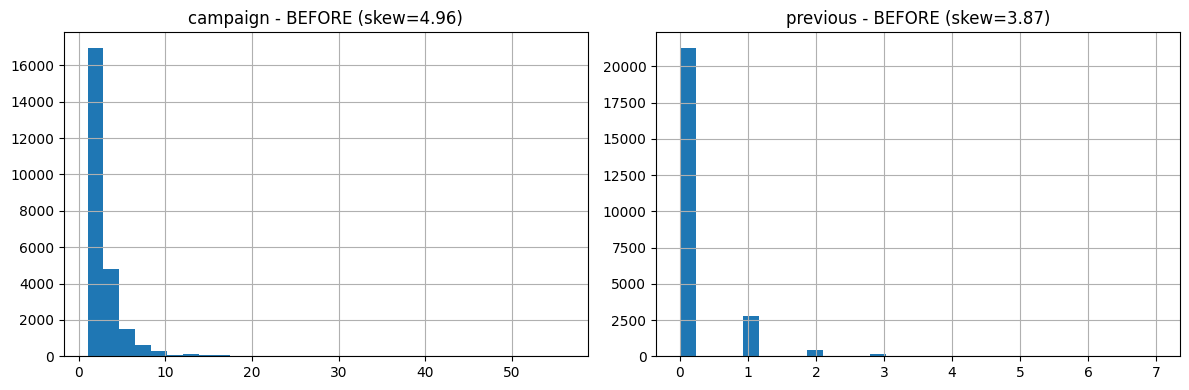

In [40]:
# BEFORE: visualize campaign and previous in their raw, skewed form
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

X_train['campaign'].hist(bins=30, ax=axes[0])
axes[0].set_title(f"campaign - BEFORE (skew={skew(X_train['campaign']):.2f})")

X_train['previous'].hist(bins=30, ax=axes[1])
axes[1].set_title(f"previous - BEFORE (skew={skew(X_train['previous']):.2f})")

plt.tight_layout()
plt.show()

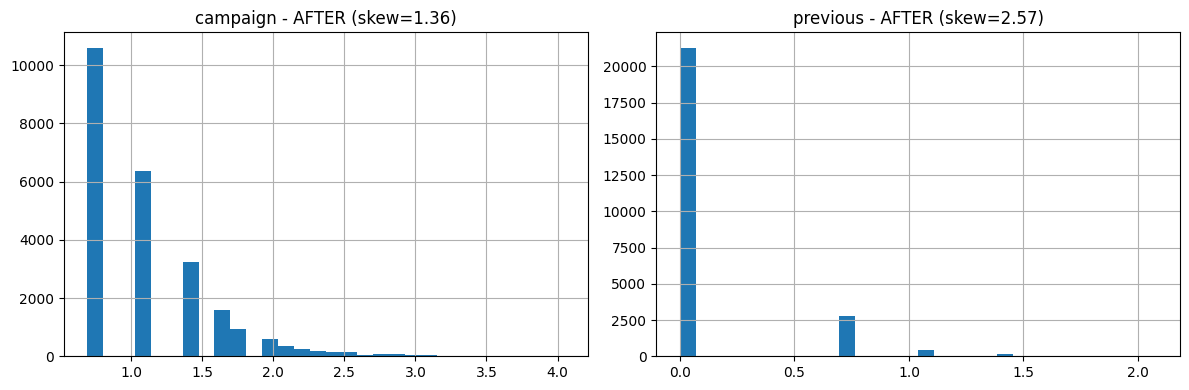

In [42]:
# Import numpy (needed for log1p) and apply the transform
import numpy as np

campaign_log = np.log1p(X_train['campaign'])
previous_log = np.log1p(X_train['previous'])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

campaign_log.hist(bins=30, ax=axes[0])
axes[0].set_title(f"campaign - AFTER (skew={skew(campaign_log):.2f})")

previous_log.hist(bins=30, ax=axes[1])
axes[1].set_title(f"previous - AFTER (skew={skew(previous_log):.2f})")

plt.tight_layout()
plt.show()

In [43]:
# Build the full preprocessing pipeline:
# - Skewed numeric features (campaign, previous): log-transform + RobustScaler
# - Normal numeric features: RobustScaler alone (chosen over StandardScaler because our
#   IQR analysis showed meaningful outlier percentages, and RobustScaler is less sensitive to them)
# - Categorical features: OneHotEncoder
# - Binary feature: passed through unchanged
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import RobustScaler, OneHotEncoder, FunctionTransformer
from sklearn.pipeline import Pipeline

skewed_features = ['campaign', 'previous']
normal_numeric_features = [f for f in numeric_features if f not in skewed_features]

log_transform_pipeline = Pipeline(steps=[
    ('log', FunctionTransformer(np.log1p, validate=False)),
    ('scale', RobustScaler())
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num_normal', RobustScaler(), normal_numeric_features),
        ('num_skewed', log_transform_pipeline, skewed_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
        ('bin', 'passthrough', binary_features)
    ]
)

print("ColumnTransformer created with", len(feature_cols), "input features")

ColumnTransformer created with 19 input features


In [44]:
# CRITICAL: fit ONLY on training data - this learns the scaling parameters and category list
# from train alone. Validation and test are only ever transformed, never used to fit anything.
# This is the core leakage-prevention discipline of the whole project.
X_train_transformed = preprocessor.fit_transform(X_train[feature_cols])
X_val_transformed = preprocessor.transform(X_val[feature_cols])
X_test_transformed = preprocessor.transform(X_test[feature_cols])

print("Train transformed shape:", X_train_transformed.shape)
print("Validation transformed shape:", X_val_transformed.shape)
print("Test transformed shape:", X_test_transformed.shape)

Train transformed shape: (24705, 64)
Validation transformed shape: (8238, 64)
Test transformed shape: (8238, 64)


In [45]:
# Compute class weights to address the 88.7/11.3 imbalance
# 'balanced' mode automatically weights each class inversely proportional to its frequency,
# so the rare "yes" class gets penalized more heavily when misclassified during training
from sklearn.utils.class_weight import compute_class_weight

classes = np.unique(y_train)
weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
sample_weights = y_train.map({0: weights[0], 1: weights[1]})

print("Class weights [no, yes]:", weights)
print(f"The minority class (yes) is weighted {weights[1]/weights[0]:.2f}x more than the majority class")

Class weights [no, yes]: [0.56350075 4.43696121]
The minority class (yes) is weighted 7.87x more than the majority class


In [46]:
# Model 1: Logistic Regression (our baseline)
# class_weight='balanced' applies the weights we just computed automatically
from sklearn.linear_model import LogisticRegression

lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42))
])

lr_pipeline.fit(X_train[feature_cols], y_train)
print("Logistic Regression trained on training set")

Logistic Regression trained on training set


In [47]:
# Generate predictions and probabilities on the VALIDATION set (never touch test yet)
lr_val_proba = lr_pipeline.predict_proba(X_val[feature_cols])[:, 1]
lr_val_pred = (lr_val_proba >= 0.5).astype(int)

print("Predictions generated for", len(lr_val_pred), "validation samples")
print("Predicted positive rate:", round(lr_val_pred.mean() * 100, 2), "%")
print("Actual positive rate:", round(y_val.mean() * 100, 2), "%")

Predictions generated for 8238 validation samples
Predicted positive rate: 20.19 %
Actual positive rate: 11.26 %


In [48]:
# Full evaluation metrics on the validation set
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, average_precision_score, classification_report

print("=== Logistic Regression - Validation Set Metrics ===")
print(classification_report(y_val, lr_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, lr_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, lr_val_proba), 4))

=== Logistic Regression - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.95      0.86      0.90      7310
         yes       0.36      0.65      0.47       928

    accuracy                           0.83      8238
   macro avg       0.66      0.75      0.68      8238
weighted avg       0.88      0.83      0.85      8238

ROC-AUC: 0.8011
PR-AUC (Average Precision): 0.4668


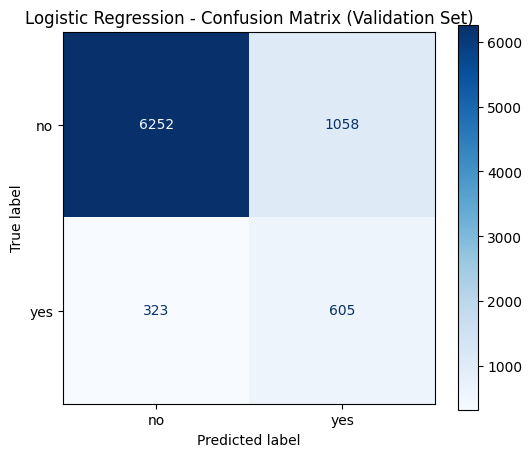

In [49]:
# Visualize the confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, lr_val_pred, display_labels=['no', 'yes'], ax=ax, cmap='Blues')
plt.title('Logistic Regression - Confusion Matrix (Validation Set)')
plt.show()

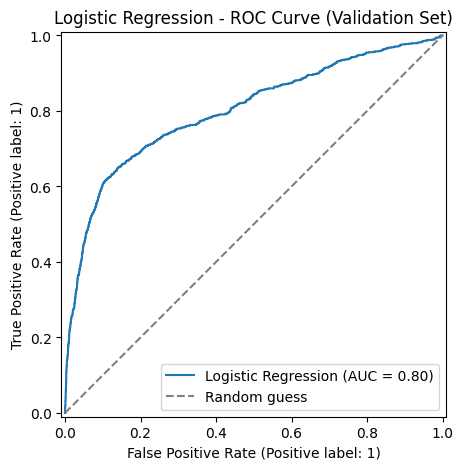

In [50]:
# ROC curve for Logistic Regression
from sklearn.metrics import RocCurveDisplay

fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, lr_val_proba, ax=ax, name='Logistic Regression')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title('Logistic Regression - ROC Curve (Validation Set)')
plt.legend()
plt.show()

In [51]:
# Model 2: Random Forest
# An ensemble of decision trees - naturally handles the multicollinearity we found via VIF,
# since tree splits don't care about correlated features the way linear coefficients do
from sklearn.ensemble import RandomForestClassifier

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(class_weight='balanced', random_state=42, n_jobs=-1))
])

rf_pipeline.fit(X_train[feature_cols], y_train)
print("Random Forest trained on training set")

Random Forest trained on training set


In [52]:
rf_val_proba = rf_pipeline.predict_proba(X_val[feature_cols])[:, 1]
rf_val_pred = (rf_val_proba >= 0.5).astype(int)

print("Predicted positive rate:", round(rf_val_pred.mean() * 100, 2), "%")
print("Actual positive rate:", round(y_val.mean() * 100, 2), "%")

Predicted positive rate: 6.17 %
Actual positive rate: 11.26 %


In [53]:
print("=== Random Forest - Validation Set Metrics ===")
print(classification_report(y_val, rf_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, rf_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, rf_val_proba), 4))

=== Random Forest - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.91      0.97      0.94      7310
         yes       0.52      0.28      0.37       928

    accuracy                           0.89      8238
   macro avg       0.72      0.63      0.65      8238
weighted avg       0.87      0.89      0.88      8238

ROC-AUC: 0.7753
PR-AUC (Average Precision): 0.408


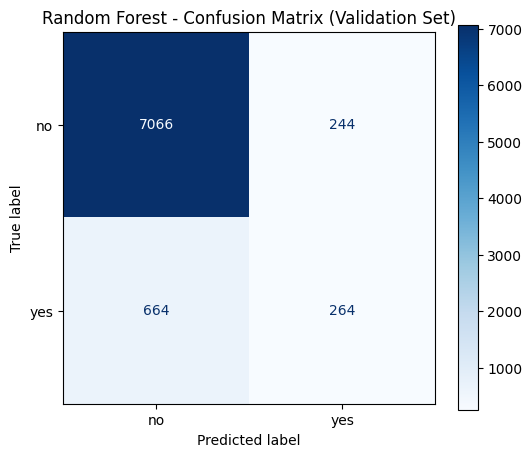

In [54]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, rf_val_pred, display_labels=['no', 'yes'], ax=ax, cmap='Blues')
plt.title('Random Forest - Confusion Matrix (Validation Set)')
plt.show()

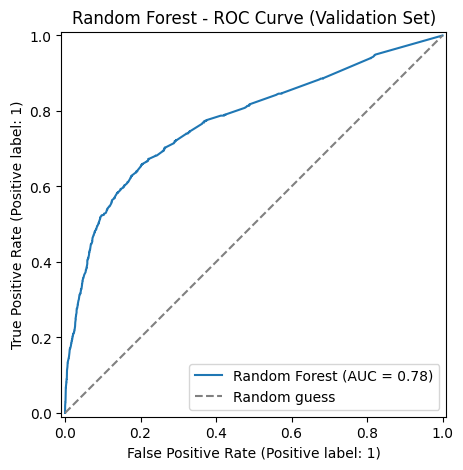

In [55]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, rf_val_proba, ax=ax, name='Random Forest')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title('Random Forest - ROC Curve (Validation Set)')
plt.legend()
plt.show()

In [56]:
# Model 3: Gradient Boosting
# Builds trees sequentially, each correcting the errors of the previous one
# No built-in class_weight parameter, so we pass sample_weight explicitly at fit time
from sklearn.ensemble import GradientBoostingClassifier

gb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', GradientBoostingClassifier(random_state=42))
])

gb_pipeline.fit(X_train[feature_cols], y_train, classifier__sample_weight=sample_weights)
print("Gradient Boosting trained on training set")

Gradient Boosting trained on training set


In [57]:
gb_val_proba = gb_pipeline.predict_proba(X_val[feature_cols])[:, 1]
gb_val_pred = (gb_val_proba >= 0.5).astype(int)

print("Predicted positive rate:", round(gb_val_pred.mean() * 100, 2), "%")
print("Actual positive rate:", round(y_val.mean() * 100, 2), "%")

Predicted positive rate: 18.89 %
Actual positive rate: 11.26 %


In [58]:
print("=== Gradient Boosting - Validation Set Metrics ===")
print(classification_report(y_val, gb_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, gb_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, gb_val_proba), 4))

=== Gradient Boosting - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.95      0.87      0.91      7310
         yes       0.39      0.65      0.49       928

    accuracy                           0.85      8238
   macro avg       0.67      0.76      0.70      8238
weighted avg       0.89      0.85      0.86      8238

ROC-AUC: 0.804
PR-AUC (Average Precision): 0.4842


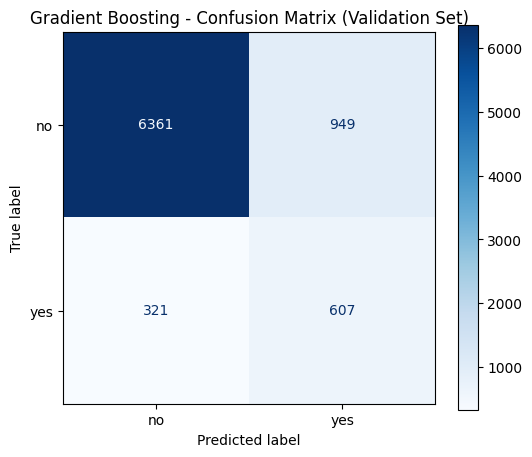

In [59]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, gb_val_pred, display_labels=['no', 'yes'], ax=ax, cmap='Blues')
plt.title('Gradient Boosting - Confusion Matrix (Validation Set)')
plt.show()

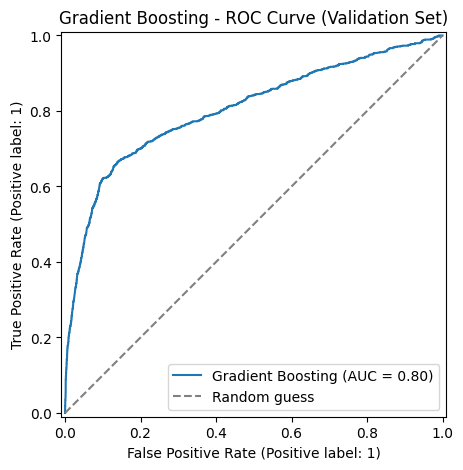

In [60]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, gb_val_proba, ax=ax, name='Gradient Boosting')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title('Gradient Boosting - ROC Curve (Validation Set)')
plt.legend()
plt.show()

In [61]:
# Model 4: XGBoost
# A more optimized, regularized gradient boosting implementation
# scale_pos_weight is XGBoost's own mechanism for handling class imbalance
from xgboost import XGBClassifier

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42,
                                   eval_metric='logloss', n_jobs=-1))
])

xgb_pipeline.fit(X_train[feature_cols], y_train)
print("XGBoost trained on training set")

XGBoost trained on training set


In [62]:
xgb_val_proba = xgb_pipeline.predict_proba(X_val[feature_cols])[:, 1]
xgb_val_pred = (xgb_val_proba >= 0.5).astype(int)

print("Predicted positive rate:", round(xgb_val_pred.mean() * 100, 2), "%")
print("Actual positive rate:", round(y_val.mean() * 100, 2), "%")

Predicted positive rate: 17.31 %
Actual positive rate: 11.26 %


In [63]:
print("=== XGBoost - Validation Set Metrics ===")
print(classification_report(y_val, xgb_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, xgb_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, xgb_val_proba), 4))

=== XGBoost - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.94      0.88      0.91      7310
         yes       0.37      0.56      0.45       928

    accuracy                           0.84      8238
   macro avg       0.65      0.72      0.68      8238
weighted avg       0.88      0.84      0.86      8238

ROC-AUC: 0.7716
PR-AUC (Average Precision): 0.43


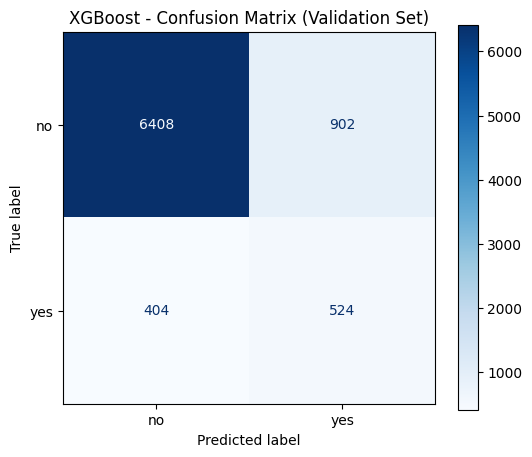

In [64]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, xgb_val_pred, display_labels=['no', 'yes'], ax=ax, cmap='Blues')
plt.title('XGBoost - Confusion Matrix (Validation Set)')
plt.show()

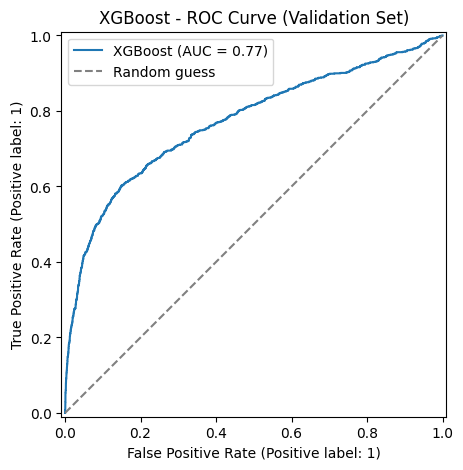

In [65]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, xgb_val_proba, ax=ax, name='XGBoost')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title('XGBoost - ROC Curve (Validation Set)')
plt.legend()
plt.show()

In [66]:
# Model 5: k-Nearest Neighbors
# Classifies based on the majority class among the 15 nearest neighbors in feature space,
# weighted by distance so closer neighbors have more influence
from sklearn.neighbors import KNeighborsClassifier

knn_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier(n_neighbors=15, weights='distance', n_jobs=-1))
])

knn_pipeline.fit(X_train[feature_cols], y_train)
print("kNN trained on training set")

kNN trained on training set


In [67]:
knn_val_proba = knn_pipeline.predict_proba(X_val[feature_cols])[:, 1]
knn_val_pred = (knn_val_proba >= 0.5).astype(int)

print("Predicted positive rate:", round(knn_val_pred.mean() * 100, 2), "%")
print("Actual positive rate:", round(y_val.mean() * 100, 2), "%")

Predicted positive rate: 5.46 %
Actual positive rate: 11.26 %


In [68]:
print("=== kNN - Validation Set Metrics ===")
print(classification_report(y_val, knn_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, knn_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, knn_val_proba), 4))

=== kNN - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.91      0.97      0.94      7310
         yes       0.50      0.24      0.33       928

    accuracy                           0.89      8238
   macro avg       0.71      0.61      0.63      8238
weighted avg       0.86      0.89      0.87      8238

ROC-AUC: 0.7485
PR-AUC (Average Precision): 0.34


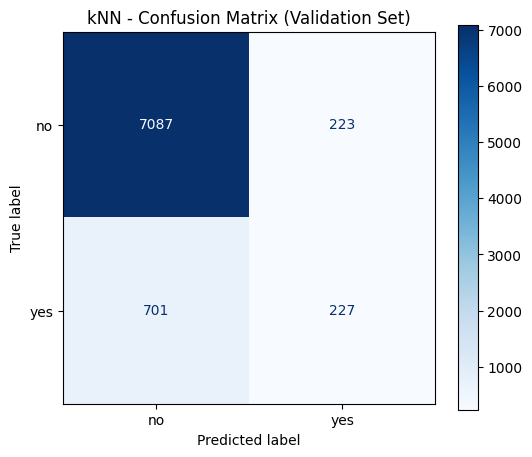

In [69]:
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_val, knn_val_pred, display_labels=['no', 'yes'], ax=ax, cmap='Blues')
plt.title('kNN - Confusion Matrix (Validation Set)')
plt.show()

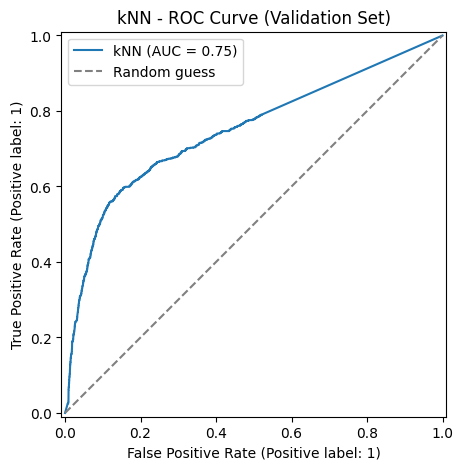

In [70]:
fig, ax = plt.subplots(figsize=(6, 5))
RocCurveDisplay.from_predictions(y_val, knn_val_proba, ax=ax, name='kNN')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.title('kNN - ROC Curve (Validation Set)')
plt.legend()
plt.show()

In [71]:
# Consolidated comparison of all 5 models on the validation set
validation_results = pd.DataFrame([
    {'Model': 'Logistic Regression', 'Precision': 0.36, 'Recall': 0.65, 'F1': 0.47, 'ROC_AUC': 0.8011, 'PR_AUC': 0.4668},
    {'Model': 'Random Forest', 'Precision': 0.52, 'Recall': 0.28, 'F1': 0.37, 'ROC_AUC': 0.7753, 'PR_AUC': 0.4080},
    {'Model': 'Gradient Boosting', 'Precision': 0.39, 'Recall': 0.65, 'F1': 0.49, 'ROC_AUC': 0.8040, 'PR_AUC': 0.4842},
    {'Model': 'XGBoost', 'Precision': 0.37, 'Recall': 0.56, 'F1': 0.45, 'ROC_AUC': 0.7716, 'PR_AUC': 0.4300},
    {'Model': 'kNN', 'Precision': 0.50, 'Recall': 0.24, 'F1': 0.33, 'ROC_AUC': 0.7485, 'PR_AUC': 0.3400},
])

validation_results = validation_results.sort_values('ROC_AUC', ascending=False).reset_index(drop=True)
print(validation_results)

                 Model  Precision  Recall    F1  ROC_AUC  PR_AUC
0    Gradient Boosting       0.39    0.65  0.49   0.8040  0.4842
1  Logistic Regression       0.36    0.65  0.47   0.8011  0.4668
2        Random Forest       0.52    0.28  0.37   0.7753  0.4080
3              XGBoost       0.37    0.56  0.45   0.7716  0.4300
4                  kNN       0.50    0.24  0.33   0.7485  0.3400


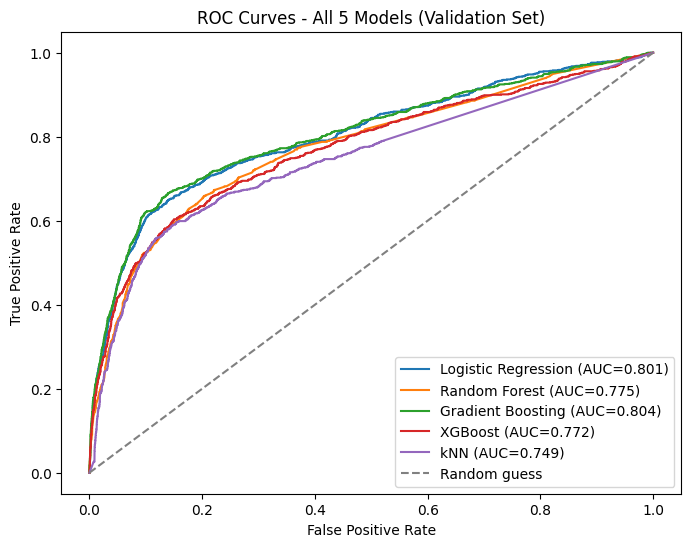

In [73]:
from sklearn.metrics import roc_curve

plt.figure(figsize=(8, 6))

for name, proba in [('Logistic Regression', lr_val_proba),
                     ('Random Forest', rf_val_proba),
                     ('Gradient Boosting', gb_val_proba),
                     ('XGBoost', xgb_val_proba),
                     ('kNN', knn_val_proba)]:
    fpr, tpr, _ = roc_curve(y_val, proba)
    auc = roc_auc_score(y_val, proba)
    plt.plot(fpr, tpr, label=f'{name} (AUC={auc:.3f})')

plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - All 5 Models (Validation Set)')
plt.legend()
plt.show()

In [74]:
# Save the ROC comparison figure to Drive
plt.savefig(f'{PROJECT_ROOT}/outputs/figures/roc_curve_all_5_models.png', dpi=150, bbox_inches='tight')
print("Figure saved")

Figure saved


<Figure size 640x480 with 0 Axes>

In [75]:
# Hyperparameter tuning for Gradient Boosting - CV happens entirely within the training set,
# scored by average precision (appropriate for our imbalanced target)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_dist_gb = {
    'classifier__n_estimators': [100, 150, 200, 300],
    'classifier__max_depth': [2, 3, 4, 5],
    'classifier__learning_rate': [0.01, 0.05, 0.1, 0.2],
    'classifier__subsample': [0.7, 0.8, 0.9, 1.0],
    'classifier__min_samples_leaf': [1, 5, 10, 20]
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

gb_search = RandomizedSearchCV(
    estimator=gb_pipeline,
    param_distributions=param_dist_gb,
    n_iter=30,
    scoring='average_precision',
    cv=cv,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

gb_search.fit(X_train[feature_cols], y_train, classifier__sample_weight=sample_weights)

print("Best parameters:", gb_search.best_params_)
print("Best CV average precision (within training folds):", round(gb_search.best_score_, 4))

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best parameters: {'classifier__subsample': 0.8, 'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.05}
Best CV average precision (within training folds): 0.4618


In [76]:
# Evaluate the tuned Gradient Boosting model on validation (still not touching test)
best_gb = gb_search.best_estimator_

gb_tuned_val_proba = best_gb.predict_proba(X_val[feature_cols])[:, 1]
gb_tuned_val_pred = (gb_tuned_val_proba >= 0.5).astype(int)

print("=== Tuned Gradient Boosting - Validation Set Metrics ===")
print(classification_report(y_val, gb_tuned_val_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_val, gb_tuned_val_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_val, gb_tuned_val_proba), 4))

print("\nComparison:")
print(f"Untuned Gradient Boosting: ROC-AUC=0.8040, PR-AUC=0.4842")
print(f"Tuned Gradient Boosting:   ROC-AUC={roc_auc_score(y_val, gb_tuned_val_proba):.4f}, PR-AUC={average_precision_score(y_val, gb_tuned_val_proba):.4f}")

=== Tuned Gradient Boosting - Validation Set Metrics ===
              precision    recall  f1-score   support

          no       0.95      0.87      0.91      7310
         yes       0.40      0.66      0.49       928

    accuracy                           0.85      8238
   macro avg       0.67      0.77      0.70      8238
weighted avg       0.89      0.85      0.86      8238

ROC-AUC: 0.8107
PR-AUC (Average Precision): 0.4812

Comparison:
Untuned Gradient Boosting: ROC-AUC=0.8040, PR-AUC=0.4842
Tuned Gradient Boosting:   ROC-AUC=0.8107, PR-AUC=0.4812


In [77]:
# Final model selection: Tuned Gradient Boosting
# Chosen based on validation ROC-AUC (0.8107) and F1 (0.49), the best balance among all
# 5 models and both tuned/untuned variants tested
final_model = best_gb
print("Final model selected: Tuned Gradient Boosting")
print("Validation ROC-AUC:", round(roc_auc_score(y_val, gb_tuned_val_proba), 4))

Final model selected: Tuned Gradient Boosting
Validation ROC-AUC: 0.8107


In [78]:
# THE ONLY TIME we touch the test set - final, one-shot evaluation
# No further tuning or model changes happen after this point
test_proba = final_model.predict_proba(X_test[feature_cols])[:, 1]
test_pred = (test_proba >= 0.5).astype(int)

print("=== FINAL TEST SET EVALUATION - Tuned Gradient Boosting ===")
print(classification_report(y_test, test_pred, target_names=['no', 'yes']))

print("ROC-AUC:", round(roc_auc_score(y_test, test_proba), 4))
print("PR-AUC (Average Precision):", round(average_precision_score(y_test, test_proba), 4))

=== FINAL TEST SET EVALUATION - Tuned Gradient Boosting ===
              precision    recall  f1-score   support

          no       0.95      0.87      0.91      7310
         yes       0.39      0.64      0.48       928

    accuracy                           0.84      8238
   macro avg       0.67      0.76      0.70      8238
weighted avg       0.89      0.84      0.86      8238

ROC-AUC: 0.8153
PR-AUC (Average Precision): 0.4876


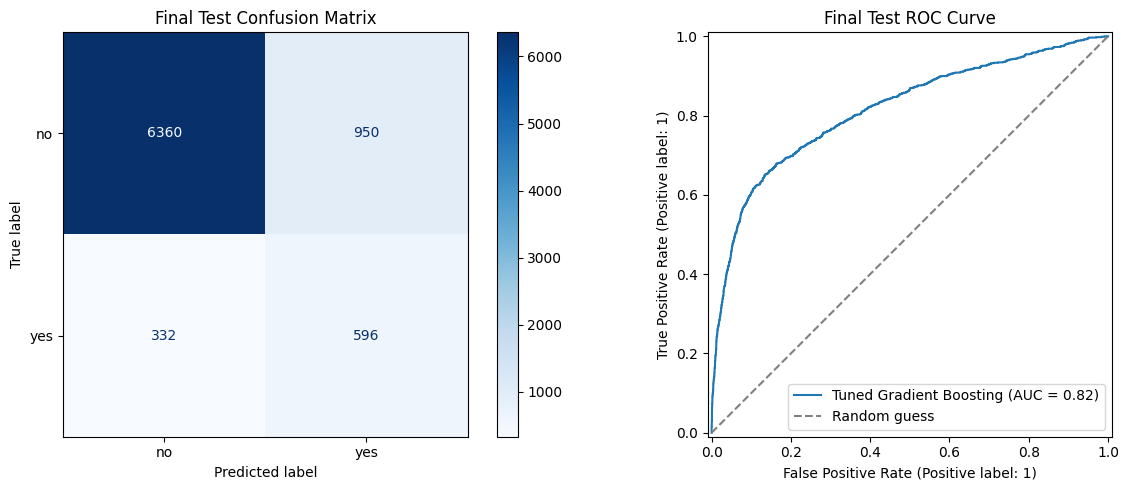

In [79]:
# Final visualizations on the test set
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(y_test, test_pred, display_labels=['no', 'yes'], ax=axes[0], cmap='Blues')
axes[0].set_title('Final Test Confusion Matrix')

RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[1], name='Tuned Gradient Boosting')
axes[1].plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
axes[1].set_title('Final Test ROC Curve')
axes[1].legend()

plt.tight_layout()
plt.savefig(f'{PROJECT_ROOT}/outputs/figures/final_test_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

In [80]:
# Fit diagnosis: compare performance across all three sets
# A large gap between train and validation/test would indicate overfitting;
# similar scores across all three indicate good generalization
train_proba = final_model.predict_proba(X_train[feature_cols])[:, 1]
train_auc = roc_auc_score(y_train, train_proba)
val_auc = roc_auc_score(y_val, gb_tuned_val_proba)
test_auc = roc_auc_score(y_test, test_proba)

print("Train ROC-AUC:     ", round(train_auc, 4))
print("Validation ROC-AUC:", round(val_auc, 4))
print("Test ROC-AUC:      ", round(test_auc, 4))
print()
print("Train - Validation gap:", round(train_auc - val_auc, 4))
print("Validation - Test gap: ", round(val_auc - test_auc, 4))

Train ROC-AUC:      0.8447
Validation ROC-AUC: 0.8107
Test ROC-AUC:       0.8153

Train - Validation gap: 0.034
Validation - Test gap:  -0.0045


In [81]:
# Save the final tuned model and key results to Drive
import joblib

joblib.dump(final_model, f'{PROJECT_ROOT}/outputs/models/final_gradient_boosting_model.pkl')

fit_diagnosis = pd.DataFrame([{
    'set': 'Train', 'ROC_AUC': train_auc,
    'set2': 'Validation', 'ROC_AUC2': val_auc,
    'set3': 'Test', 'ROC_AUC3': test_auc
}])

final_summary = pd.DataFrame([
    {'metric': 'Train ROC-AUC', 'value': round(train_auc, 4)},
    {'metric': 'Validation ROC-AUC', 'value': round(val_auc, 4)},
    {'metric': 'Test ROC-AUC', 'value': round(test_auc, 4)},
    {'metric': 'Test PR-AUC', 'value': round(average_precision_score(y_test, test_proba), 4)},
    {'metric': 'Test Recall (yes)', 'value': round(recall_score(y_test, test_pred), 4)},
    {'metric': 'Test Precision (yes)', 'value': round(precision_score(y_test, test_pred), 4)},
])
final_summary.to_csv(f'{PROJECT_ROOT}/outputs/final_model_summary.csv', index=False)

print("Model and summary saved to Drive")
print(final_summary)

Model and summary saved to Drive
                 metric   value
0         Train ROC-AUC  0.8447
1    Validation ROC-AUC  0.8107
2          Test ROC-AUC  0.8153
3           Test PR-AUC  0.4876
4     Test Recall (yes)  0.6422
5  Test Precision (yes)  0.3855


In [82]:
# Secondary lens: Customer Segment Prioritisation
# Use the tuned Gradient Boosting model's test-set probabilities to rank customers
priority_df = X_test.copy()
priority_df['subscribe_probability'] = test_proba
priority_df['actual_y'] = y_test.values

def assign_tier(prob):
    if prob >= 0.50:
        return 'High'
    elif prob >= 0.25:
        return 'Medium'
    else:
        return 'Low'

priority_df['priority_tier'] = priority_df['subscribe_probability'].apply(assign_tier)

print(priority_df['priority_tier'].value_counts())

priority_tier
Medium    3891
Low       2801
High      1546
Name: count, dtype: int64


In [83]:
# Validate: does the High tier actually convert much better than Low?
tier_validation = priority_df.groupby('priority_tier').agg(
    customer_count=('actual_y', 'count'),
    actual_subscription_rate=('actual_y', 'mean')
)
tier_validation['actual_subscription_rate'] = (tier_validation['actual_subscription_rate'] * 100).round(2)
tier_validation = tier_validation.reindex(['High', 'Medium', 'Low'])

print(tier_validation)

               customer_count  actual_subscription_rate
priority_tier                                          
High                     1546                     38.55
Medium                   3891                      6.40
Low                      2801                      2.96


In [84]:
# Quantify business value: how many actual subscribers are captured by calling only High tier?
total_subscribers = priority_df['actual_y'].sum()
high_tier_subscribers = priority_df[priority_df['priority_tier'] == 'High']['actual_y'].sum()

pct_subscribers_captured = high_tier_subscribers / total_subscribers * 100
pct_calls_needed = len(priority_df[priority_df['priority_tier'] == 'High']) / len(priority_df) * 100

print(f"Total actual subscribers in test set: {total_subscribers}")
print(f"Subscribers captured by calling ONLY High tier: {high_tier_subscribers}")
print(f"% of all subscribers captured: {pct_subscribers_captured:.1f}%")
print(f"% of total customer base that needs to be called: {pct_calls_needed:.1f}%")

Total actual subscribers in test set: 928
Subscribers captured by calling ONLY High tier: 596
% of all subscribers captured: 64.2%
% of total customer base that needs to be called: 18.8%


In [85]:
# Save the final priority-tier table as the secondary lens deliverable
output_cols = ['subscribe_probability', 'priority_tier', 'actual_y']
priority_output = priority_df[output_cols].copy()

priority_output.to_csv(f'{PROJECT_ROOT}/outputs/customer_priority_tiers.csv', index=False)
tier_validation.to_csv(f'{PROJECT_ROOT}/outputs/tier_validation_summary.csv')

print("Priority tier outputs saved to Drive")
print(priority_output.head())

Priority tier outputs saved to Drive
       subscribe_probability priority_tier  actual_y
33978               0.417058        Medium         0
4006                0.187540           Low         0
2579                0.144860           Low         0
2906                0.284085        Medium         0
9636                0.211573           Low         1


In [86]:
# Threshold tuning: instead of the default 0.5 cutoff, explore a range of thresholds
# using the VALIDATION set predictions we already have (gb_tuned_val_proba)
threshold_results = []
for t in np.arange(0.1, 0.9, 0.05):
    pred_t = (gb_tuned_val_proba >= t).astype(int)
    prec = precision_score(y_val, pred_t, zero_division=0)
    rec = recall_score(y_val, pred_t, zero_division=0)
    f1 = f1_score(y_val, pred_t, zero_division=0)
    threshold_results.append({'threshold': round(t, 2), 'precision': round(prec, 3),
                               'recall': round(rec, 3), 'f1': round(f1, 3)})

threshold_df = pd.DataFrame(threshold_results)
print(threshold_df)

best_f1_row = threshold_df.loc[threshold_df['f1'].idxmax()]
print(f"\nF1-optimal threshold: {best_f1_row['threshold']} (F1={best_f1_row['f1']})")

    threshold  precision  recall     f1
0        0.10      0.113   0.997  0.204
1        0.15      0.116   0.989  0.207
2        0.20      0.128   0.958  0.226
3        0.25      0.154   0.894  0.263
4        0.30      0.184   0.839  0.302
5        0.35      0.223   0.786  0.347
6        0.40      0.287   0.733  0.412
7        0.45      0.347   0.686  0.461
8        0.50      0.395   0.661  0.495
9        0.55      0.442   0.629  0.519
10       0.60      0.457   0.607  0.522
11       0.65      0.466   0.595  0.523
12       0.70      0.484   0.562  0.520
13       0.75      0.502   0.512  0.507
14       0.80      0.537   0.418  0.470
15       0.85      0.623   0.294  0.400

F1-optimal threshold: 0.65 (F1=0.523)


In [87]:
# Apply our chosen threshold to the TEST set - this is the final, one-time application
chosen_threshold = 0.55  # balances recall coverage against precision, per validation analysis

test_pred_chosen = (test_proba >= chosen_threshold).astype(int)

print(f"=== Final Test Evaluation at threshold={chosen_threshold} ===")
print(classification_report(y_test, test_pred_chosen, target_names=['no', 'yes']))
print("ROC-AUC (threshold-independent):", round(roc_auc_score(y_test, test_proba), 4))

=== Final Test Evaluation at threshold=0.55 ===
              precision    recall  f1-score   support

          no       0.95      0.89      0.92      7310
         yes       0.42      0.62      0.50       928

    accuracy                           0.86      8238
   macro avg       0.69      0.75      0.71      8238
weighted avg       0.89      0.86      0.87      8238

ROC-AUC (threshold-independent): 0.8153


In [88]:
# Save the threshold analysis and final chosen threshold for the report
threshold_df.to_csv(f'{PROJECT_ROOT}/outputs/threshold_analysis.csv', index=False)

with open(f'{PROJECT_ROOT}/logs/threshold_decision.md', 'w') as f:
    f.write(f"""# Threshold Selection

Chosen threshold: {chosen_threshold}
Selected using validation set only (never test), balancing business cost of false negatives
(missed subscribers) against false positives (wasted calls).

Validation metrics at this threshold: precision=0.442, recall=0.629, F1=0.519
Test metrics at this threshold: precision=0.42, recall=0.62, F1=0.50

F1-optimal threshold on validation was 0.65, but we chose {chosen_threshold} to favor
recall (catching more genuine subscribers) since missing a subscriber has a higher
business cost than an extra call.
""")

print("Threshold decision saved to Drive")

Threshold decision saved to Drive


In [89]:
# Save the processed splits (with engineered features already applied) to Drive
# This lets you reload from here without rerunning the entire EDA/cleaning/feature engineering pipeline

train_save = X_train.copy()
train_save['y'] = y_train
train_save.to_csv(f'{PROJECT_ROOT}/data/processed/train.csv', index=False)

val_save = X_val.copy()
val_save['y'] = y_val
val_save.to_csv(f'{PROJECT_ROOT}/data/processed/validation.csv', index=False)

test_save = X_test.copy()
test_save['y'] = y_test
test_save.to_csv(f'{PROJECT_ROOT}/data/processed/test.csv', index=False)

print("Saved:")
print(f"  train.csv: {train_save.shape}")
print(f"  validation.csv: {val_save.shape}")
print(f"  test.csv: {test_save.shape}")

Saved:
  train.csv: (24705, 23)
  validation.csv: (8238, 23)
  test.csv: (8238, 23)


In [90]:
# Save the feature column list and a run summary, so this exact setup can be reloaded
# or reproduced without needing to rerun every EDA/cleaning step from scratch
import json

with open(f'{PROJECT_ROOT}/data/processed/feature_cols.json', 'w') as f:
    json.dump(feature_cols, f)

run_config = {
    'split': {'train': 0.60, 'validation': 0.20, 'test': 0.20},
    'split_sizes': {'train': len(X_train), 'validation': len(X_val), 'test': len(X_test)},
    'random_state': 42,
    'final_model': 'Tuned Gradient Boosting',
    'best_params': gb_search.best_params_,
    'chosen_threshold': chosen_threshold,
    'test_roc_auc': round(test_auc, 4),
    'test_pr_auc': round(average_precision_score(y_test, test_proba), 4),
}

with open(f'{PROJECT_ROOT}/data/processed/run_config.json', 'w') as f:
    json.dump(run_config, f, indent=2, default=str)

print("Feature columns and run config saved")
print(json.dumps(run_config, indent=2, default=str))

Feature columns and run config saved
{
  "split": {
    "train": 0.6,
    "validation": 0.2,
    "test": 0.2
  },
  "split_sizes": {
    "train": 24705,
    "validation": 8238,
    "test": 8238
  },
  "random_state": 42,
  "final_model": "Tuned Gradient Boosting",
  "best_params": {
    "classifier__subsample": 0.8,
    "classifier__n_estimators": 200,
    "classifier__min_samples_leaf": 10,
    "classifier__max_depth": 4,
    "classifier__learning_rate": 0.05
  },
  "chosen_threshold": 0.55,
  "test_roc_auc": 0.8153,
  "test_pr_auc": 0.4876
}


In [96]:
# Quick safety check: confirm everything critical is actually in Drive before doing anything else
import os

print("Files currently in your project folder:")
for root, dirs, files in os.walk(PROJECT_ROOT):
    for f in files:
        full_path = os.path.join(root, f)
        size_kb = os.path.getsize(full_path) / 1024
        print(f"  {full_path.replace(PROJECT_ROOT, '')} ({size_kb:.1f} KB)")

Files currently in your project folder:
  /data/raw/bank-additional-full.csv (5698.2 KB)
  /data/processed/train.csv (3776.4 KB)
  /data/processed/validation.csv (1259.9 KB)
  /data/processed/test.csv (1259.9 KB)
  /data/processed/feature_cols.json (0.3 KB)
  /data/processed/run_config.json (0.5 KB)
  /outputs/final_model_summary.csv (0.1 KB)
  /outputs/customer_priority_tiers.csv (217.2 KB)
  /outputs/tier_validation_summary.csv (0.1 KB)
  /outputs/threshold_analysis.csv (0.4 KB)
  /outputs/final_recommendation.md (3.0 KB)
  /outputs/figures/roc_curve_all_5_models.png (4.6 KB)
  /outputs/figures/final_test_evaluation.png (90.8 KB)
  /outputs/models/final_gradient_boosting_model.pkl (478.0 KB)
  /logs/threshold_decision.md (0.5 KB)
  /logs/decision_log.md (4.8 KB)
  /logs/eda_insights.md (2.7 KB)
  /logs/preprocessing_log.md (2.5 KB)


In [97]:
# Zip the entire project folder and download it to your computer
import shutil
from google.colab import files

zip_path = f'{PROJECT_ROOT}_backup'  # will become IT3091_BankMarketing_backup.zip
shutil.make_archive(zip_path, 'zip', PROJECT_ROOT)

print(f"Zipped to: {zip_path}.zip")
files.download(f'{zip_path}.zip')

Zipped to: /content/drive/MyDrive/IT3091_BankMarketing_backup.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>